In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import logistic
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

## 2. import Data

In [19]:
weight_height_data = pd.read_csv(filepath_or_buffer="E:\Projects\Project Datasets\Data Science by AI John\weightheight.csv")
weight_height_data

<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\Acer\AppData\Local\Temp\ipykernel_6504\499521334.py:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  weight_height_data = pd.read_csv(filepath_or_buffer="E:\Projects\Project Datasets\Data Science by AI John\weightheight.csv")


,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


## 3. Data Understanding

In [12]:
weight_height_data.shape

(10000, 3)

In [13]:
weight_height_data.isna().sum()

Gender    0
Height    0
Weight    0
dtype: int64

In [14]:
weight_height_data.dtypes

Gender     object
Height    float64
Weight    float64
dtype: object

## 4. Data Preparation

* Lets do feature engineering
    * it is nothing but a concept of whatever you do with features, we call it as feature engineering
        * Feature deletion
        * Feature addition
        * Feature selection
        * Feature decomposition
        * Feature Transformation
### We are interested to convert units of heights and weights from inches to CM and heights from pounds to KG

In [20]:
wh_data_copy = weight_height_data.copy()

In [17]:
del wh_data_copy['Gender']

In [18]:
wh_data_copy

,Height,Weight
0,73.847017,241.893563
1,68.781904,162.310473
2,74.110105,212.740856
3,71.730978,220.042470
4,69.881796,206.349801
...,...,...
9995,66.172652,136.777454
9996,67.067155,170.867906
9997,63.867992,128.475319
9998,69.034243,163.852461


In [21]:
wh_data_copy['Height_CM'] = wh_data_copy['Height']*2.54
wh_data_copy['Weight_KG'] = wh_data_copy['Weight']/2.205
wh_data_copy

,Gender,Height,Weight,Height_CM,Weight_KG
0,Male,73.847017,241.893563,187.571423,109.702296
1,Male,68.781904,162.310473,174.706036,73.610192
2,Male,74.110105,212.740856,188.239668,96.481114
3,Male,71.730978,220.042470,182.196685,99.792504
4,Male,69.881796,206.349801,177.499761,93.582676
...,...,...,...,...,...
9995,Female,66.172652,136.777454,168.078536,62.030591
9996,Female,67.067155,170.867906,170.350573,77.491114
9997,Female,63.867992,128.475319,162.224700,58.265451
9998,Female,69.034243,163.852461,175.346978,74.309506


In [24]:
wh_data_copy.drop(labels=['Height', 'Weight'], axis=1, inplace=True)

In [25]:
wh_data_copy

,Height_CM,Weight_CM
0,187.571423,109.702296
1,174.706036,73.610192
2,188.239668,96.481114
3,182.196685,99.792504
4,177.499761,93.582676
...,...,...
9995,168.078536,62.030591
9996,170.350573,77.491114
9997,162.224700,58.265451
9998,175.346978,74.309506


## Let's perform Assumption test
### Assumptions
1. Normality Test
2. Linearity test
3. MultiCollinearity Test
4. No Auto Regression
5. Homoscadacity test
6. Zero Residual Mean test

<Axes: ylabel='Frequency'>

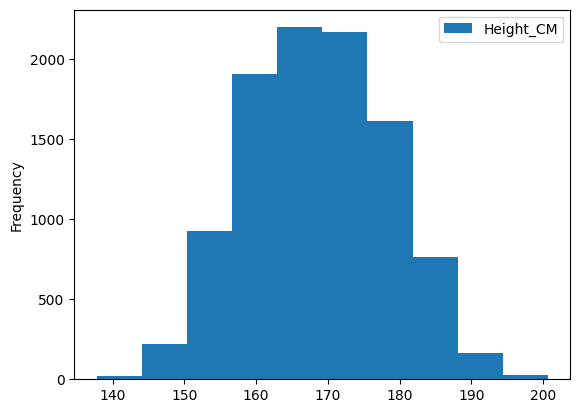

In [28]:
# Normality Test
wh_data_copy.plot(kind='hist', x='Weight_CM', y='Height_CM')

<Axes: xlabel='Height_CM', ylabel='Weight_CM'>

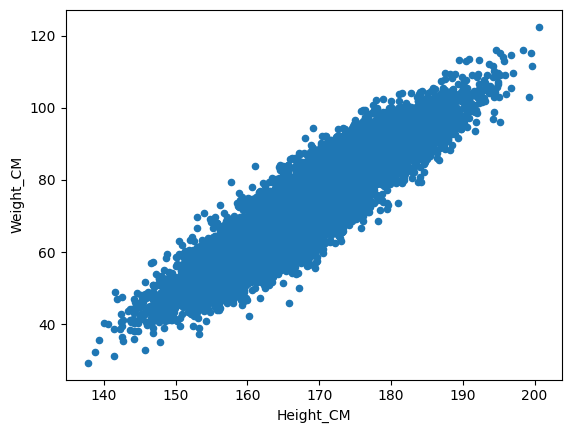

In [29]:
# Linearity test

wh_data_copy.plot(kind='scatter', x='Height_CM', y='Weight_CM')

## 6. Model Building

In [30]:
# MultiCollinearity Test
wh_data_copy.corr()

,Height_CM,Weight_CM
Height_CM,1.000000,0.924756
Weight_CM,0.924756,1.000000


In [27]:
X = wh_data_copy[['Weight_KG']]
Y = wh_data_copy[['Height_CM']]

## 7. Model training


In [28]:
linear_model = LinearRegression()
linear_model.fit(X,Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.62]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Weight_KG']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[123.13]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [30]:
linear_model.coef_

array([[0.62062922]])

In [31]:
linear_model.intercept_

array([123.13387264])

## 8. Model Testing (manual)

In [32]:
#Y = mx + c
#If weight is 95kg, what will be the Height

(0.62062922*95) + 123.13387264

182.09364854

In [36]:
#If weight is 75kg, what will be the Height

(0.62062922*75) + 123.13387264

169.68106414

In [35]:
#If weight is 95kg, what will be the Height

(0.62062922*110) + 123.13387264

191.40308684000001

## 8.1 Model Testing (Automatic)

In [37]:
X_test = pd.DataFrame(data = [95,75,110])
linear_model.predict(X_test)

C:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[182.09364855],
       [169.68106414],
       [191.40308685]])

# 8.3 Model Evaluation

In [56]:
#X_test = pd.DataFrame(data = [95,75,110])
y_pred = linear_model.predict(X)
# y_pred = pd.DataFrame(y_pred)
y_pred

array([[191.21832319],
       [168.81850845],
       [183.01287094],
       ...,
       [159.29511386],
       [169.25252357],
       [155.12206037]], shape=(10000, 1))

In [64]:
Y

,Height_CM
0,187.571423
1,174.706036
2,188.239668
3,182.196685
4,177.499761
...,...
9995,168.078536
9996,170.350573
9997,162.224700
9998,175.346978


In [65]:
y_pred

array([[191.21832319],
       [168.81850845],
       [183.01287094],
       ...,
       [159.29511386],
       [169.25252357],
       [155.12206037]], shape=(10000, 1))

In [66]:
error = Y - y_pred
error

,Height_CM
0,-3.646900
1,5.887528
2,5.226797
3,-2.871331
4,-3.714254
...,...
9995,6.446666
9996,-0.876549
9997,2.929586
9998,6.094454


In [67]:
error.mean()

Height_CM    1.664375e-14
dtype: float64

## Let's check Assumption 5: Homoscadacity Test
* It is a plot between input an error

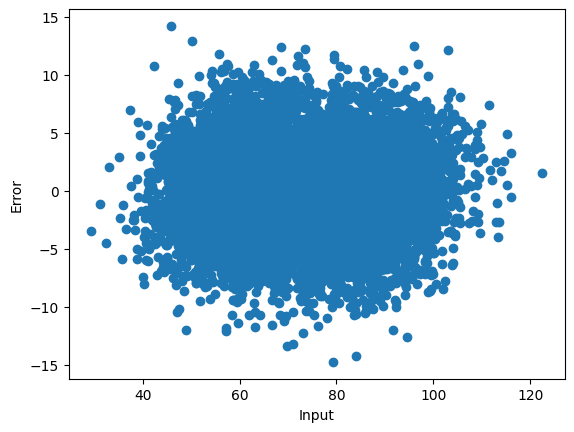

In [68]:
plt.scatter(x = wh_data_copy['Weight_KG'], y = error)
plt.xlabel('Input')
plt.ylabel('Error')
plt.show()

## Let's check Assumption 6: Zero Residual Mean Test across the fitted line
* It is a plot between Output and Predicted Output

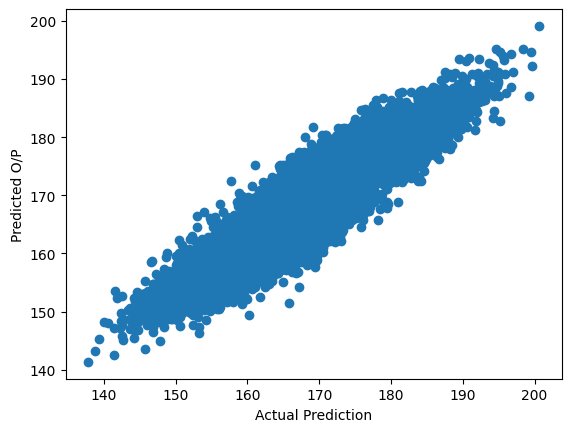

In [70]:
plt.scatter(x = Y, y = y_pred)
plt.xlabel('Actual Prediction')
plt.ylabel('Predicted O/P')
plt.show()

## 9. Model Deployment

In [35]:
from pickle import dump

In [72]:
dump(linear_model, open ('linear_model.pkl','wb'))

In [73]:
from pickle import load


In [74]:
loaded_intel = load(open ('linear_model.pkl','rb'))

In [75]:
loaded_intel.predict(X_test)

C:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[182.09364855],
       [169.68106414],
       [191.40308685]])

# Logistic Regression
### Exact transformation of Linear Regression
* Sigmiod Curve = 1/1+e ^ -y

## Classification Problem


## 2. Data Collection

In [9]:
gender_data = pd.read_csv(filepath_or_buffer="E:\Projects\Project Datasets\Data Science by AI John\weightheight.csv")
gender_data

<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\Acer\AppData\Local\Temp\ipykernel_18484\4031584013.py:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  gender_data = pd.read_csv(filepath_or_buffer="E:\Projects\Project Datasets\Data Science by AI John\weightheight.csv")


,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


## 3. Data Understanding

In [4]:
gender_data.dtypes

Gender     object
Height    float64
Weight    float64
dtype: object

## 4. Data Preparation

In [14]:
gender_data['Gender'] = gender_data['Gender'].replace(to_replace=['Male','Female'], value = [0,1])

C:\Users\Acer\AppData\Local\Temp\ipykernel_18484\76850059.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  gender_data['Gender'] = gender_data['Gender'].replace(to_replace=['Male','Female'], value = [0,1])


In [15]:
gender_data.dtypes

Gender      int64
Height    float64
Weight    float64
dtype: object

In [16]:
gender_data['Height'] = gender_data['Height']*2.54
gender_data['Weight'] = gender_data['Weight']*2.205

## 5. Model Building

In [17]:
gender_data

,Gender,Height,Weight
0,0,187.571423,533.375307
1,0,174.706036,357.894592
2,0,188.239668,469.093587
3,0,182.196685,485.193647
4,0,177.499761,455.001310
...,...,...,...
9995,1,168.078536,301.594286
9996,1,170.350573,376.763732
9997,1,162.224700,283.288078
9998,1,175.346978,361.294677


In [18]:
X = gender_data.drop('Gender', axis=1)
Y = gender_data[['Gender']]

## 6. Model Training

In [26]:
logistic_model = LogisticRegression()
logistic_model.fit(X, Y)

C:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [27]:
logistic_model.coef_

array([[ 0.18838967, -0.08926965]])

In [28]:
logistic_model.intercept_

array([0.00157558])

In [32]:
logistic_model.predict(X)

array([0, 1, 0, ..., 1, 1, 1], shape=(10000,))

In [31]:
logistic_model.predict_proba(X)

array([[9.99995338e-01, 4.66165522e-06],
       [2.75826007e-01, 7.24173993e-01],
       [9.98360688e-01, 1.63931193e-03],
       ...,
       [5.09694295e-03, 9.94903057e-01],
       [3.13784839e-01, 6.86215161e-01],
       [6.94336525e-04, 9.99305663e-01]], shape=(10000, 2))

In [33]:
y_predict = logistic_model.predict(X)

In [34]:
from sklearn.metrics import accuracy_score
accuracy_score(Y, y_predict)

0.9195

## 9. Model Deployment

In [36]:
dump(logistic_model, open ('logistic_model.pkl','wb'))